### ANALYSIS OF KAGGLE DATASET ###

### import libraries ###

In [1]:
import pandas as pd
import numpy as np
import nltk
import matplotlib.pyplot as plt
%matplotlib inline


### Read the dataset ###

In [2]:
kaggle=pd.read_csv(r'Downloads/all_kaggle_datasets.csv')

kaggle.shape


(13020, 37)

### Displaying first 5 records ###

In [3]:
kaggle.shape

(13020, 37)

In [4]:
kaggle.head()

,categories,commonFileTypes,creatorName,creatorUrl,creatorUserId,currentDatasetVersionId,currentDatasetVersionNumber,datasetId,datasetSize,datasetUrl,...,ownerUrl,ownerUserId,scriptCount,scriptsUrl,thumbnailImageUrl,title,topicCount,type,viewCount,voteButton
0,"{'categories': [{'id': 13213, 'name': 'survey ...","[{'fileType': 'csv', 'count': 3, 'totalSize': ...",Paul Mooney,/paultimothymooney,1314380,161079,5,70947,4043536,/kaggle/kaggle-survey-2018,...,/kaggle,NaN,190,/kaggle/kaggle-survey-2018/kernels,https://storage.googleapis.com/kaggle-datasets...,2018 Kaggle ML & DS Survey Challenge,12,fileset,274306,"{'totalVotes': 678, 'hasAlreadyVotedUp': False..."
1,"{'categories': [{'id': 13205, 'name': 'text mi...","[{'fileType': 'other', 'count': 20, 'totalSize...",Jason King,/jkkphys,459483,194523,1,83790,968989653,/jkkphys/english-wikipedia-articles-20170820-m...,...,/jkkphys,459483.0,11,/jkkphys/english-wikipedia-articles-20170820-m...,https://storage.googleapis.com/kaggle-datasets...,English Wikipedia Articles 2017-08-20 Models,0,fileset,176,"{'totalVotes': 2, 'hasAlreadyVotedUp': False, ..."
2,"{'categories': [{'id': 11102, 'name': 'busines...","[{'fileType': 'csv', 'count': 1, 'totalSize': ...",Mehdi Dagdoug,/mehdidag,1227281,59109,1,38809,5621145,/mehdidag/black-friday,...,/mehdidag,1227281.0,40,/mehdidag/black-friday/kernels,https://storage.googleapis.com/kaggle-datasets...,Black Friday,4,fileset,80770,"{'totalVotes': 298, 'hasAlreadyVotedUp': False..."
3,"{'categories': [{'id': 1209, 'name': 'governme...","[{'fileType': 'other', 'count': 1, 'totalSize'...",Chris Crawford,/crawford,484516,150301,18,45286,45177047,/center-for-policing-equity/data-science-for-good,...,/center-for-policing-equity,NaN,54,/center-for-policing-equity/data-science-for-g...,https://storage.googleapis.com/kaggle-datasets...,Data Science for Good: Center for Policing Equity,27,fileset,52192,"{'totalVotes': 282, 'hasAlreadyVotedUp': False..."
4,"{'categories': [{'id': 2200, 'name': 'arts and...","[{'fileType': 'other', 'count': 2, 'totalSize'...",Danil,/thedownhill,1914606,36285,2,28335,609430422,/thedownhill/art-images-drawings-painting-scul...,...,/thedownhill,1914606.0,5,/thedownhill/art-images-drawings-painting-scul...,https://storage.googleapis.com/kaggle-datasets...,Art Images: Drawing/Painting/Sculptures/Engrav...,0,fileset,4086,"{'totalVotes': 42, 'hasAlreadyVotedUp': False,..."


In [5]:
kaggle.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13020 entries, 0 to 13019
Data columns (total 37 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   categories                   13020 non-null  object 
 1   commonFileTypes              13020 non-null  object 
 2   creatorName                  13020 non-null  object 
 3   creatorUrl                   13020 non-null  object 
 4   creatorUserId                13020 non-null  int64  
 5   currentDatasetVersionId      13020 non-null  int64  
 6   currentDatasetVersionNumber  13020 non-null  int64  
 7   datasetId                    13020 non-null  int64  
 8   datasetSize                  13020 non-null  int64  
 9   datasetUrl                   13020 non-null  object 
 10  dateUpdated                  13020 non-null  object 
 11  diffType                     13020 non-null  object 
 12  downloadCount                13020 non-null  int64  
 13  forumUrl        

In [6]:
kaggle.isnull().sum()

categories                         0
commonFileTypes                    0
creatorName                        0
creatorUrl                         0
creatorUserId                      0
currentDatasetVersionId            0
currentDatasetVersionNumber        0
datasetId                          0
datasetSize                        0
datasetUrl                         0
dateUpdated                        0
diffType                           0
downloadCount                      0
forumUrl                           0
isCollaborator                     0
isDeleted                          0
isFailed                           0
isFeatured                         0
isHidden                           0
isPrivate                          0
isSuperFeatured                    0
licenseName                        0
licenseShortName                   0
maintainerOrganization         12161
overview                        6793
ownerAvatarUrl                     0
ownerName                          0
o

In [7]:
kaggle.fillna('0',inplace=True)
kaggle.isnull().sum()

categories                     0
commonFileTypes                0
creatorName                    0
creatorUrl                     0
creatorUserId                  0
currentDatasetVersionId        0
currentDatasetVersionNumber    0
datasetId                      0
datasetSize                    0
datasetUrl                     0
dateUpdated                    0
diffType                       0
downloadCount                  0
forumUrl                       0
isCollaborator                 0
isDeleted                      0
isFailed                       0
isFeatured                     0
isHidden                       0
isPrivate                      0
isSuperFeatured                0
licenseName                    0
licenseShortName               0
maintainerOrganization         0
overview                       0
ownerAvatarUrl                 0
ownerName                      0
ownerUrl                       0
ownerUserId                    0
scriptCount                    0
scriptsUrl

In [8]:
kaggle.corr()

,creatorUserId,currentDatasetVersionId,currentDatasetVersionNumber,datasetId,datasetSize,downloadCount,isCollaborator,isDeleted,isFailed,isFeatured,isHidden,isPrivate,isSuperFeatured,scriptCount,topicCount,viewCount
creatorUserId,1.000000,0.193565,-0.311872,0.384687,-0.008571,-0.114791,NaN,NaN,NaN,-0.236223,NaN,NaN,-0.011297,-0.085012,-0.125466,-0.114645
currentDatasetVersionId,0.193565,1.000000,0.457394,0.900993,-0.005164,-0.105042,NaN,NaN,NaN,-0.089010,NaN,NaN,0.032189,-0.053351,-0.108471,-0.103198
currentDatasetVersionNumber,-0.311872,0.457394,1.000000,0.175101,-0.003305,-0.011730,NaN,NaN,NaN,0.139020,NaN,NaN,0.012121,0.003986,-0.004275,-0.010933
datasetId,0.384687,0.900993,0.175101,1.000000,-0.003846,-0.151155,NaN,NaN,NaN,-0.226235,NaN,NaN,0.023122,-0.082252,-0.161013,-0.149391
datasetSize,-0.008571,-0.005164,-0.003305,-0.003846,1.000000,-0.001832,NaN,NaN,NaN,0.025988,NaN,NaN,-0.000490,0.007765,0.007253,0.005342
downloadCount,-0.114791,-0.105042,-0.011730,-0.151155,-0.001832,1.000000,NaN,NaN,NaN,0.288678,NaN,NaN,0.056502,0.657335,0.717145,0.929342
isCollaborator,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
isDeleted,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
isFailed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
isFeatured,-0.236223,-0.089010,0.139020,-0.226235,0.025988,0.288678,NaN,NaN,NaN,1.000000,NaN,NaN,0.092274,0.179063,0.291085,0.282580


In [9]:
import seaborn as sns

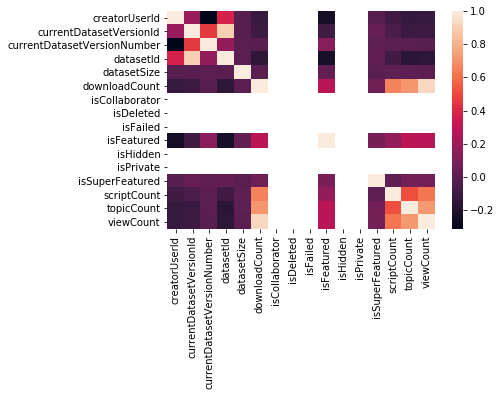

In [10]:
sns.heatmap(kaggle.corr())
plt.show()

### Displaying unique creators ###

In [11]:
A=kaggle["creatorName"].unique()
print("number of creators:",len(A))
for i in range(len(A)):
    print(A[i])
print("")


number of creators: 6863
Paul Mooney
Jason King
Mehdi Dagdoug
Chris Crawford
Danil
Szamil
JustinR
Jan Charles Maghirang Adona
Andre Sionek
Martin Ellis
Lavanya Gupta
Rob Mulla
Jacob Baruch
Evan N (GFN)
Arunava
Manu Siddhartha
Noah Daniels
Kaggle Team
Rachael Tatman
Dan Ofer
Gary Broughton
Jason Miller
Ray Hall
Thomas Edge
zackthoutt
Ivan Felipe Rodriguez
hocnx
Don George
Jessica Li
beluga
Megan Risdal
Ankit
Jesús Utrera
Dênnis Dantas
Luiz Gerosa
Sohier Dane
Rishabh Misra
Aparna Shastry
JohnM
Rob Harrand
caganseval
Mihai Oltean
Stefano Leone
James Ko
MKD
szrlee
Randi H Griffin
Jiun Yen
Roxanne Russell
Kevin Mader
Vijay Choudhary
rounak041993
Ramanathan 
Timo Bozsolik
Idris
AaronSchlegel
Yogesh Patil
Shanshan Lu 
Ghaleb Dweikat
Joost Hazelzet
Xavier
ChrisC
Damien BENESCHI
Rituparna
André Araújo
Tomás Mantecón
Nicholle @ Datafiniti
Clorichel
SHAHIR
Diego Vicente
Sijo VM
ClaudioDavi
Pranav Badami
Akash
Patrick Stetz
Tadhg Fitzgerald
gverzea
Boris Marjanovic
Kyubyong Park
JobsPikr
Nick Broo

### Displaying unique dataseturl  ###

In [12]:
A=kaggle["datasetUrl"].unique()
print("number of dataset:",len(A))
for i in range(len(A)):
    print(A[i])
print("")


number of dataset: 13020
/kaggle/kaggle-survey-2018
/jkkphys/english-wikipedia-articles-20170820-models
/mehdidag/black-friday
/center-for-policing-equity/data-science-for-good
/thedownhill/art-images-drawings-painting-sculpture-engraving
/szamil/who-suicide-statistics
/jrobischon/wikipedia-movie-plots
/septa97/100k-courseras-course-reviews-dataset
/olistbr/brazilian-ecommerce
/martinellis/nhl-game-data
/census/census-bureau-usa
/lava18/google-play-store-apps
/robikscube/hourly-energy-consumption
/jacobbaruch/nba-player-of-the-week
/footprintnetwork/national-footprint-accounts-2018
/iarunava/happy-house-dataset
/sid321axn/amazon-alexa-reviews
/huffingtonpost/pollster-congressional-districts
/cityofLA/los-angeles-international-airport-data
/unitednations/un-general-debates
/danofer/sarcasm
/san-francisco/sf-police-calls-for-service-and-incidents
/jkkphys/english-wikipedia-articles-20170820-sqlite
/gjbroughton/christmas-recipes
/millerintllc/eeg-microexperiment
/yarnedia/2018-nba-playbyp

In [13]:
import re

### Displaying number of dataset created by the creators ###

In [14]:
dresult=""
cname=kaggle["creatorName"].unique()
#print(len(cname))
for i in range(0,len(cname)):
    cresult=re.sub(r'[^\x00-\x7f]',"",cname[i])
    print(cresult)
    print('\n')
    dscount=kaggle[kaggle.creatorName==cresult].groupby(["datasetUrl"]).count()
    df=pd.DataFrame(dscount)
    print(df.iloc[0:100,0:1])
    df.shape
    #dresult+=cresult
print("\n")
#print(dresult)


Paul Mooney


                                                    categories
datasetUrl                                                    
/LondonDataStore/london-crime                                1
/alexattia/the-simpsons-characters-dataset                   1
/bigquery/chrome-user-experience-report                      1
/bigquery/chrome-ux-report-country-in                        1
/bigquery/chrome-ux-report-country-us                        1
/bigquery/genomics-cannabis                                  1
/bigquery/google-analytics-sample                            1
/bigquery/open-images                                        1
/bigquery/samples                                            1
/bls/bls                                                     1
/census/census-bureau-international                          1
/census/census-bureau-usa                                    1
/chicago/chicago-crime                                       1
/chicago/chicago-taxi-trips-bq           

### Displaying number of dataset based on categories ###

In [15]:
dresult=""
cname=kaggle["datasetUrl"].unique()
#print(len(cname))
for i in range(0,len(cname)):
    cresult=re.sub(r'[^\x00-\x7f]',"",cname[i])
    print(cresult)
    print('\n')
    dscount=kaggle[kaggle.datasetUrl==cresult].groupby(["categories"]).count()
    df=pd.DataFrame(dscount)
    print(df.iloc[0:100,0:1])
    df.shape
    #dresult+=cresult
print("\n")
#print(dresult)


/kaggle/kaggle-survey-2018


                                                    commonFileTypes
categories                                                         
{'categories': [{'id': 13213, 'name': 'survey a...                1
/jkkphys/english-wikipedia-articles-20170820-models


                                                    commonFileTypes
categories                                                         
{'categories': [{'id': 13205, 'name': 'text min...                1
/mehdidag/black-friday


                                                    commonFileTypes
categories                                                         
{'categories': [{'id': 11102, 'name': 'business...                1
/center-for-policing-equity/data-science-for-good


                                                    commonFileTypes
categories                                                         
{'categories': [{'id': 1209, 'name': 'governmen...                1
/thedownhill/art-images-

In [16]:
def word_count(str):
    counts=dict()
    words=str.split(",")
    for word in words:
        if word in counts:
            counts[word] +=1
        else:
            counts[word]=1
    return counts


### WORD COUNT FOR DISPLAYING CATEGORIES COUNT ###

In [17]:
catname=kaggle['categories']
catname
b=[]
c=""
d=""
e=""
for i in range(0,13020):
    b=catname[i]
    #print(b)
    str="name"
    if str in b:
        x=b.split(",")
        y=x[1]
        z=y.split(":")
        c=z[1]
        #print(c)
        d=(c[2:-1])+","
        if d in e:
            e+=d
        else:   
            e+=d
        #print(z[1])
    #print(e)
print(word_count(e))


{'survey analysis': 1, 'text mining': 7, 'business': 142, 'government agencies': 42, 'arts and entertainment': 7, 'social sciences': 8, 'film': 29, 'brazil': 32, 'databases': 38, 'government': 18, 'video games': 56, 'research': 26, 'united states': 69, 'world': 79, 'deep learning': 8, 'beginner': 20, 'politics': 98, 'socrata': 678, 'international relations': 4, 'humor': 8, 'crime': 85, 'food and drink': 76, 'neuroscience': 7, 'basketball': 36, 'visual arts': 6, 'critical theory': 5, 'ecology': 9, 'climate': 96, 'asia': 2, 'finance': 139, 'time series': 56, 'economics': 157, 'india': 55, 'multiclass classification': 3, 'law': 13, 'libraries': 6, 'healthcare': 117, 'europe': 64, 'earth sciences': 11, 'pollution': 10, 'news agencies': 35, 'linguistics': 95, 'transport': 14, 'web sites': 15, 'astronomy': 19, 'automobiles': 18, 'popular culture': 43, 'programming languages': 6, 'biology': 15, 'stochastic processes': 2, 'literature': 13, 'olympic games': 6, 'oceans': 7, 'learning': 9, 'oncol

### DISPLAYING CATEGORIES WITHOUT DUPLICATES WITH THEIR COUNT ###

In [18]:
b=[]
c=""
d=""
e=""
for i in range(0,13020):
    b=catname[i]
    #print(b)
    str="name"
    if str in b:
        x=b.split(",")
        y=x[1]
        z=y.split(":")
        c=z[1]
        print(c)
        d=(c[2:-1])+","
        if d in e:
            e+=''
        else:   
            e+=d
        #print(z[1])
    #print(e)
print(word_count(e))


 'survey analysis'
 'text mining'
 'business'
 'government agencies'
 'arts and entertainment'
 'social sciences'
 'film'
 'brazil'
 'databases'
 'government'
 'video games'
 'research'
 'united states'
 'world'
 'deep learning'
 'beginner'
 'politics'
 'socrata'
 'international relations'
 'humor'
 'crime'
 'databases'
 'food and drink'
 'neuroscience'
 'basketball'
 'visual arts'
 'politics'
 'critical theory'
 'ecology'
 'climate'
 'beginner'
 'climate'
 'asia'
 'business'
 'finance'
 'climate'
 'business'
 'climate'
 'climate'
 'climate'
 'time series'
 'research'
 'research'
 'climate'
 'economics'
 'india'
 'multiclass classification'
 'law'
 'business'
 'business'
 'climate'
 'world'
 'economics'
 'libraries'
 'socrata'
 'united states'
 'healthcare'
 'socrata'
 'socrata'
 'healthcare'
 'brazil'
 'economics'
 'europe'
 'business'
 'economics'
 'brazil'
 'government agencies'
 'economics'
 'healthcare'
 'research'
 'finance'
 'earth sciences'
 'pollution'
 'news agencies'
 'resea

### WORD CLOUD FOR CATEGORIES ###


In [19]:
from wordcloud import WordCloud
import seaborn as sns
from nltk.corpus import stopwords
A=kaggle['categories'].unique()

b=[]
c=""
d=""
e=""
for i in range(0,len(A)):
    b=A[i]
    str="name"
    if str in b:
        x=b.split(",")
        y=x[1]
        z=y.split(":")
        c=z[1]
        d=(c[2:-1])+","
        if d in e:
            e+=''
        else:   
            e+=d
        #print(z[1])
#print(e)       


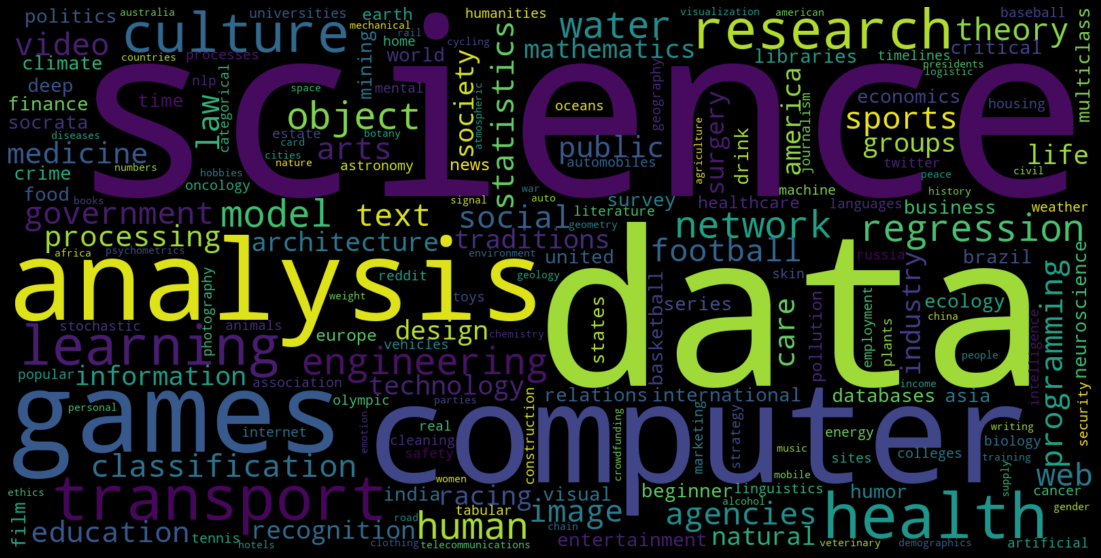

<Figure size 432x288 with 0 Axes>

In [20]:
wordcloud=WordCloud(width=1600,height=800,margin=0).generate(e)
plt.figure(figsize=(20,10),facecolor='k')
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
#plt.margins(x=0,y=0)
#plt.tight_layout(pad=0)
plt.show(wordcloud)
plt.savefig('creator.png',facecolor='k',bbox_inches='tight')


### WORD CLOUD FOR CREATORS ###


6863


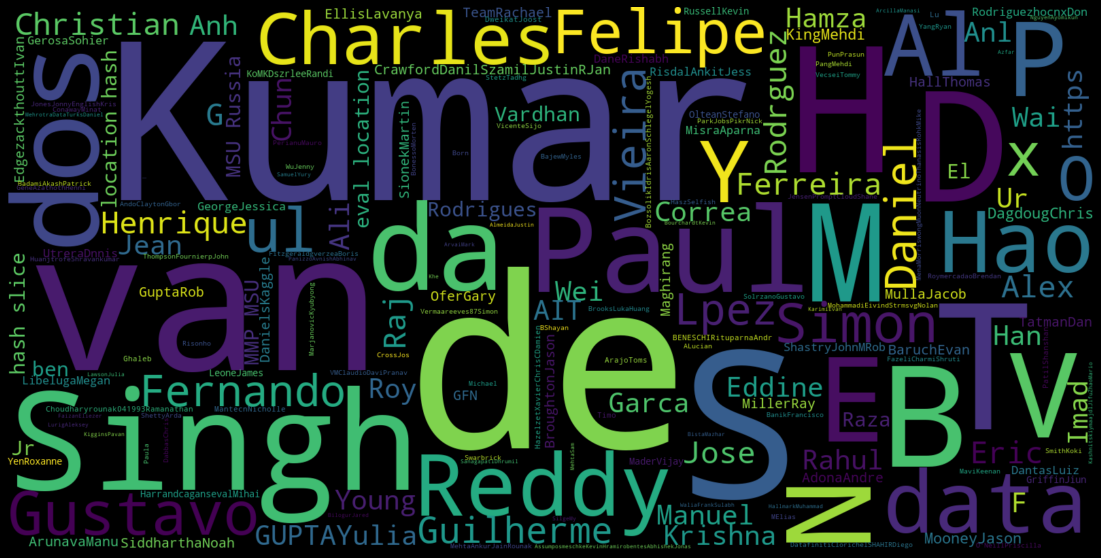

<Figure size 432x288 with 0 Axes>

In [21]:
dresult=""
cname=kaggle["creatorName"].unique()
print(len(cname))
for i in range(0,len(cname)):
    cresult=re.sub(r'[^\x00-\x7f]',"",cname[i])
    dresult+=cresult
#print(dresult)
wordcloud=WordCloud(width=1600,height=800,margin=0).generate(dresult)
plt.figure(figsize=(20,10),facecolor='k')
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
#plt.margins(x=0,y=0)
#plt.tight_layout(pad=0)
plt.show(wordcloud)
plt.savefig('creator.png',facecolor='k',bbox_inches='tight')


### Top 10 download count ###

In [22]:
cdc=kaggle.groupby(["downloadCount"]).categories.unique().value_counts().nlargest(10)
print(cdc)



[{'categories': [], 'type': 'dataset'}]                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              121
[{'categories': [{'id': 11104, 'name': 'crime', 'fullPath': 'society and social sciences > society > crime', 'listingUrl': '/datasets?group=public&tagids=11104', 'description': 'A crime is an unlawful act punishable by a state or other authority. Explore datasets, kernels, and competitions related to white collar crime, global terrorism, and more in

### Top 10 votecount for categories ###

In [23]:
cdc=kaggle.groupby(["voteButton"]).categories.unique().value_counts().nlargest(10)
print(cdc)


[{'categories': [], 'type': 'dataset'}]                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 

### Top 10 viewcount based on categories ###

In [24]:
cdc=kaggle.groupby(["viewCount"]).categories.unique().value_counts().nlargest(10)
print(cdc)


[{'categories': [], 'type': 'dataset'}]                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 

In [25]:
A=kaggle["ownerName"].unique()
print("number of owners:",len(A))
for i in range(len(A)):
    print(A[i])
print("")


number of owners: 7061
Kaggle
Jason King
Mehdi Dagdoug
Center for Policing Equity
Danil
Szamil
JustinR
Jan Charles Maghirang Adona
Olist
Martin Ellis
US Census Bureau
Lavanya Gupta
Rob Mulla
Jacob Baruch
Global Footprint Network
Arunava
Manu Siddhartha
The Huffington Post
City of Los Angeles
United Nations
Dan Ofer
City of San Francisco
Gary Broughton
Jason Miller
Ray Hall
Google
Thomas Edge
zackthoutt
Ivan Felipe Rodriguez
FiveThirtyEight
hocnx
Don George
Geospatial Information Authority of Japan
Google BigQuery
beluga
OECD
Ankit
Jesús Utrera
Libraries.io
Centers for Medicare & Medicaid Services
City of Chicago
Dênnis Dantas
European Parliament
Luiz Gerosa
World Bank
National Library of Medicine
Internal Revenue Service
NOAA
Open AQ
The GDELT Project
Rishabh Misra
Aparna Shastry
JohnM
Rob Harrand
NYC Open Data
US Bureau of Labor Statistics
Department of Transportation
City of Oakland
caganseval
Mihai Oltean
Stefano Leone
Github
James Ko
MKD
DataSF
Paul Mooney
szrlee
U.S. Forest Servic

In [26]:
dresult=""
cname=kaggle["creatorName"].unique()
#print(len(cname))
for i in range(0,len(cname)):
    cresult=re.sub(r'[^\x00-\x7f]',"",cname[i])
    print(cresult)
    print('\n')
    dscount=kaggle[kaggle.creatorName==cresult].groupby(["ownerName"]).count()
    df=pd.DataFrame(dscount)
    print(df.iloc[0:100,0:1])
    df.shape
    #dresult+=cresult
print("\n")
#print(dresult)

Paul Mooney


                                          categories
ownerName                                           
Centers for Medicare & Medicaid Services           3
City of Chicago                                    2
Data.gov                                           1
DataSF                                             1
Google BigQuery                                    7
Internal Revenue Service                           1
Kaggle                                             1
Libraries.io                                       1
London Data Store                                  1
Mark Kaghazgarian                                  1
NOAA                                               1
NYC Open Data                                      1
National Library of Medicine                       1
Paul Mooney                                       12
Stack Overflow                                     1
The Metropolitan Museum of Art                     1
U.S. Forest Service             

In [27]:
Cname=kaggle["creatorName"].unique()
print("number of creators:",len(Cname))
Durl=kaggle["datasetUrl"].unique()
print("Creator Name \t\t\t DatasetUrl")
for i in range(len(Cname)):
    print(Cname[i],"=",Durl[i])
print("")


number of creators: 6863
Creator Name 			 DatasetUrl
Paul Mooney = /kaggle/kaggle-survey-2018
Jason King = /jkkphys/english-wikipedia-articles-20170820-models
Mehdi Dagdoug = /mehdidag/black-friday
Chris Crawford = /center-for-policing-equity/data-science-for-good
Danil = /thedownhill/art-images-drawings-painting-sculpture-engraving
Szamil = /szamil/who-suicide-statistics
JustinR = /jrobischon/wikipedia-movie-plots
Jan Charles Maghirang Adona = /septa97/100k-courseras-course-reviews-dataset
Andre Sionek = /olistbr/brazilian-ecommerce
Martin Ellis = /martinellis/nhl-game-data
Lavanya Gupta = /census/census-bureau-usa
Rob Mulla = /lava18/google-play-store-apps
Jacob Baruch = /robikscube/hourly-energy-consumption
Evan N (GFN) = /jacobbaruch/nba-player-of-the-week
Arunava = /footprintnetwork/national-footprint-accounts-2018
Manu Siddhartha = /iarunava/happy-house-dataset
Noah Daniels = /sid321axn/amazon-alexa-reviews
Kaggle Team = /huffingtonpost/pollster-congressional-districts
Rachael Ta

In [28]:
def getIndexes(dfObj, value):
     
    # Empty list
    listOfPos = []
     
    # isin() method will return a dataframe with
    # boolean values, True at the positions   
    # where element exists
    result = dfObj.isin([value])
     
    # any() method will return
    # a boolean series
    seriesObj = result.any()
 
    # Get list of column names where
    # element exists
    columnNames = list(seriesObj[seriesObj == True].index)
    
    # Iterate over the list of columns and
    # extract the row index where element exists
    for col in columnNames:
        if(col=="downloadCount"):
            rows = list(result['downloadCount'][result['downloadCount'] == True].index)
            for row in rows:
                listOfPos.append((row, col))
        else:
            continue
             
    # This list contains a list tuples with
    # the index of element in the dataframe
    return listOfPos
 



### Downloadcount ###

DataSet Id 310 in Dataframe  total Downloads 88635
DataSet Id 138 in Dataframe  total Downloads 76293
DataSet Id 63 in Dataframe  total Downloads 64462
DataSet Id 19 in Dataframe  total Downloads 41107
DataSet Id 894 in Dataframe  total Downloads 40902
DataSet Id 34 in Dataframe  total Downloads 37880
DataSet Id 504 in Dataframe  total Downloads 37186
DataSet Id 1442 in Dataframe  total Downloads 36598
DataSet Id 180 in Dataframe  total Downloads 31867
DataSet Id 1346 in Dataframe  total Downloads 31095



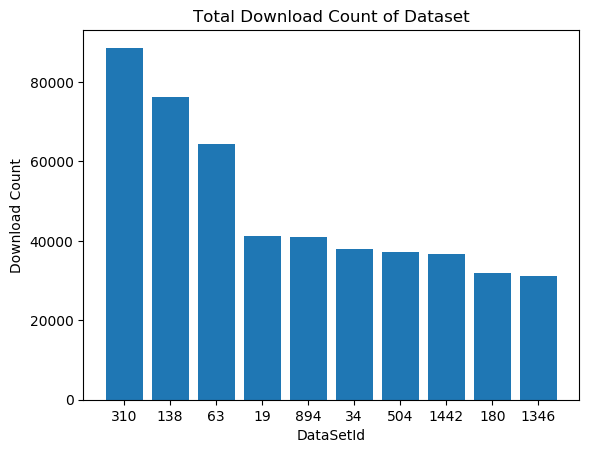

In [29]:
df=pd.read_csv(r'Downloads/all_kaggle_datasets.csv')
plt.rcdefaults()
aa=[]
xaxis=[]
yaxis=[]
aa=np.array(df["downloadCount"].nlargest(10))
ser=pd.Series(aa)
for i in range(len(ser)):
    listOfPositions = getIndexes(df, ser[i]) 
    yaxis.append(ser[i])
    for j in range(len(listOfPositions)):
        
        y=np.array(listOfPositions[j])
        #print(y)
       
        z=int(y[j])
        print('DataSet Id %s in Dataframe  total Downloads %s'%(df.iloc[z,7],ser[i]))
        xaxis.append(df.iloc[z,7])
print("")
plt.xticks(range(len(xaxis)),xaxis)
plt.xlabel("DataSetId")
plt.ylabel('Download Count')
plt.title('Total Download Count of Dataset')
plt.bar(range(len(yaxis)),yaxis)
plt.show()

In [30]:
def getTCIndexes(dfObj, value):
     
    # Empty list
    listOfPos = []
     
    # isin() method will return a dataframe with
    # boolean values, True at the positions   
    # where element exists
    result = dfObj.isin([ser[i]])
     
    # any() method will return
    # a boolean series
    seriesObj = result.any()
 
    # Get list of column names where
    # element exists
    columnNames = list(seriesObj[seriesObj == True].index)
    #print(columnNames)
    
    # Iterate over the list of columns and
    # extract the row index where element exists
    for col in columnNames:
        if(col=="topicCount"):
            rows = list(result['topicCount'][result['topicCount'] == True].index)
            for row in rows:
                listOfPos.append((row, col))
        else:
            continue
    
    return listOfPos
 


### topic count ###

DataSet Id 63 in Dataframe  total Topic Count 87
DataSet Id 138 in Dataframe  total Topic Count 50
DataSet Id 12414 in Dataframe  total Topic Count 47
DataSet Id 23690 in Dataframe  total Topic Count 39
DataSet Id 792 in Dataframe  total Topic Count 37
DataSet Id 310 in Dataframe  total Topic Count 35
DataSet Id 9 in Dataframe  total Topic Count 32
DataSet Id 34 in Dataframe  total Topic Count 29
DataSet Id 1963 in Dataframe  total Topic Count 28
DataSet Id 45286 in Dataframe  total Topic Count 27



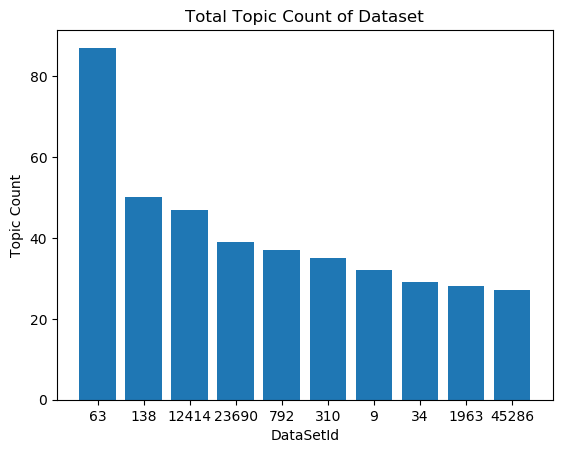

In [31]:
plt.rcdefaults()
aa=[]
xaxis=[]
yaxis=[]
aa=np.array(df["topicCount"].nlargest(10))
ser=pd.Series(aa)
for i in range(len(ser)):
    listOfPositions = getTCIndexes(df, ser[i]) 
    yaxis.append(ser[i])
    
    for j in range(len(listOfPositions)):
        
        y=np.array(listOfPositions[j])
        
        z=int(y[j])
        print('DataSet Id %s in Dataframe  total Topic Count %s'%(df.iloc[z,7],ser[i]))
        xaxis.append(df.iloc[z,7])
print("")
plt.xticks(range(len(xaxis)),xaxis)
plt.xlabel("DataSetId")
plt.ylabel('Topic Count')
plt.title('Total Topic Count of Dataset')
plt.bar(range(len(yaxis)),yaxis)
plt.show()

In [32]:
def getVCIndexes(dfObj, value):
     
    # Empty list
    listOfPos = []
     
    # isin() method will return a dataframe with
    # boolean values, True at the positions   
    # where element exists
    result = dfObj.isin([ser[i]])
     
    # any() method will return
    # a boolean series
    seriesObj = result.any()
 
    # Get list of column names where
    # element exists
    columnNames = list(seriesObj[seriesObj == True].index)
    #print(columnNames)
    
    # Iterate over the list of columns and
    # extract the row index where element exists
    for col in columnNames:
        if(col=="viewCount"):
            rows = list(result['viewCount'][result['viewCount'] == True].index)
            for row in rows:
                listOfPos.append((row, col))
        else:
            continue
    
    return listOfPos

### view count ###

DataSet Id 310 in Dataframe  total View Count 997159
DataSet Id 138 in Dataframe  total View Count 539476
DataSet Id 63 in Dataframe  total View Count 527757
DataSet Id 70947 in Dataframe  total View Count 274306
DataSet Id 1994 in Dataframe  total View Count 258962
DataSet Id 504 in Dataframe  total View Count 258504
DataSet Id 1346 in Dataframe  total View Count 246640
DataSet Id 19 in Dataframe  total View Count 215955
DataSet Id 34 in Dataframe  total View Count 213503
DataSet Id 180 in Dataframe  total View Count 209227



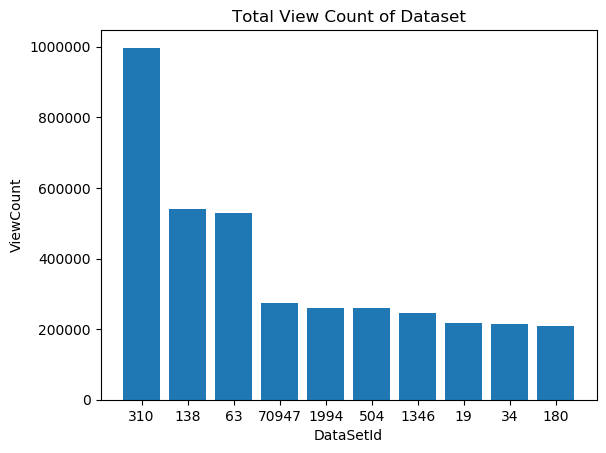

In [33]:
plt.rcdefaults()
aa=[]
xaxis=[]
yaxis=[]
aa=np.array(df["viewCount"].nlargest(10))
ser=pd.Series(aa)
for i in range(len(ser)):
    listOfPositions = getVCIndexes(df, ser[i]) 
    yaxis.append(ser[i])
    
    for j in range(len(listOfPositions)):
        
        y=np.array(listOfPositions[j])
        
        z=int(y[j])
        print('DataSet Id %s in Dataframe  total View Count %s'%(df.iloc[z,7],ser[i]))
        xaxis.append(df.iloc[z,7])
print("")

plt.xticks(range(len(xaxis)),xaxis)
plt.xlabel("DataSetId")
plt.ylabel('ViewCount')
plt.title('Total View Count of Dataset')
plt.bar(range(len(yaxis)),yaxis)
plt.show()

Title Credit Card Fraud Detection in Dataframe  total Downloads 88635
Title TMDB 5000 Movie Dataset in Dataframe  total Downloads 76293
Title European Soccer Database in Dataframe  total Downloads 64462
Title Iris Species in Dataframe  total Downloads 41107
Title World Happiness Report in Dataframe  total Downloads 40902
Title Lending Club Loan Data in Dataframe  total Downloads 37880
Title Global Terrorism Database in Dataframe  total Downloads 37186
Title Wine Reviews in Dataframe  total Downloads 36598
Title Breast Cancer Wisconsin (Diagnostic) Data Set in Dataframe  total Downloads 31867
Title Bitcoin Historical Data in Dataframe  total Downloads 31095



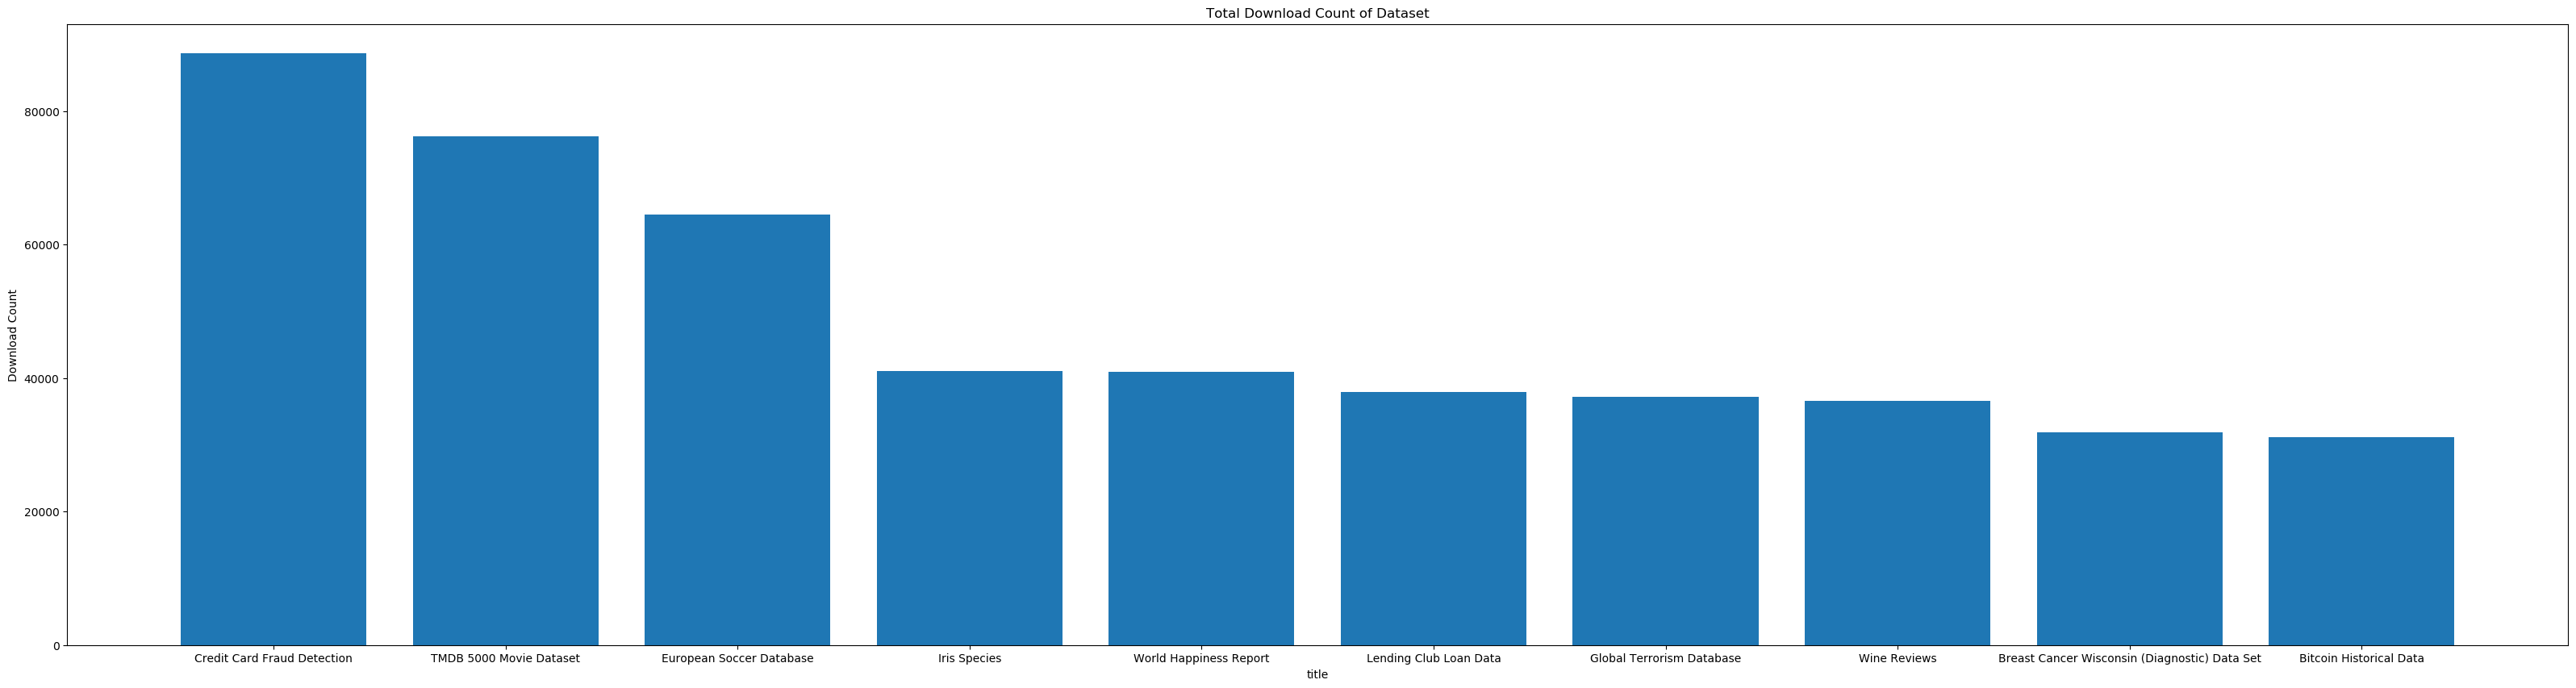

In [34]:
df=pd.read_csv(r'Downloads/all_kaggle_datasets.csv')
plt.rcdefaults()
aa=[]
xaxis=[]
yaxis=[]
aa=np.array(df["downloadCount"].nlargest(10))
ser=pd.Series(aa)
for i in range(len(ser)):
    listOfPositions = getIndexes(df, ser[i]) 
    yaxis.append(ser[i])
    for j in range(len(listOfPositions)):
        
        y=np.array(listOfPositions[j])
        #print(y)
       
        z=int(y[j])
        print('Title %s in Dataframe  total Downloads %s'%(df.iloc[z,32],ser[i]))
        xaxis.append(df.iloc[z,32])
print("")
plt.figure(figsize=(40,10))
plt.xticks(range(len(xaxis)),xaxis)
#plt.figure(figsize=(40,10))
plt.xlabel("title")
#plt.figure(figsize=(40,10))
plt.ylabel('Download Count')
plt.title('Total Download Count of Dataset')
plt.bar(range(len(yaxis)),yaxis)
plt.show()

Title Credit Card Fraud Detection in Dataframe  total View Count 997159
Title TMDB 5000 Movie Dataset in Dataframe  total View Count 539476
Title European Soccer Database in Dataframe  total View Count 527757
Title 2018 Kaggle ML & DS Survey Challenge in Dataframe  total View Count 274306
Title Banks data in Dataframe  total View Count 258962
Title Global Terrorism Database in Dataframe  total View Count 258504
Title Bitcoin Historical Data in Dataframe  total View Count 246640
Title Iris Species in Dataframe  total View Count 215955
Title Lending Club Loan Data in Dataframe  total View Count 213503
Title Breast Cancer Wisconsin (Diagnostic) Data Set in Dataframe  total View Count 209227



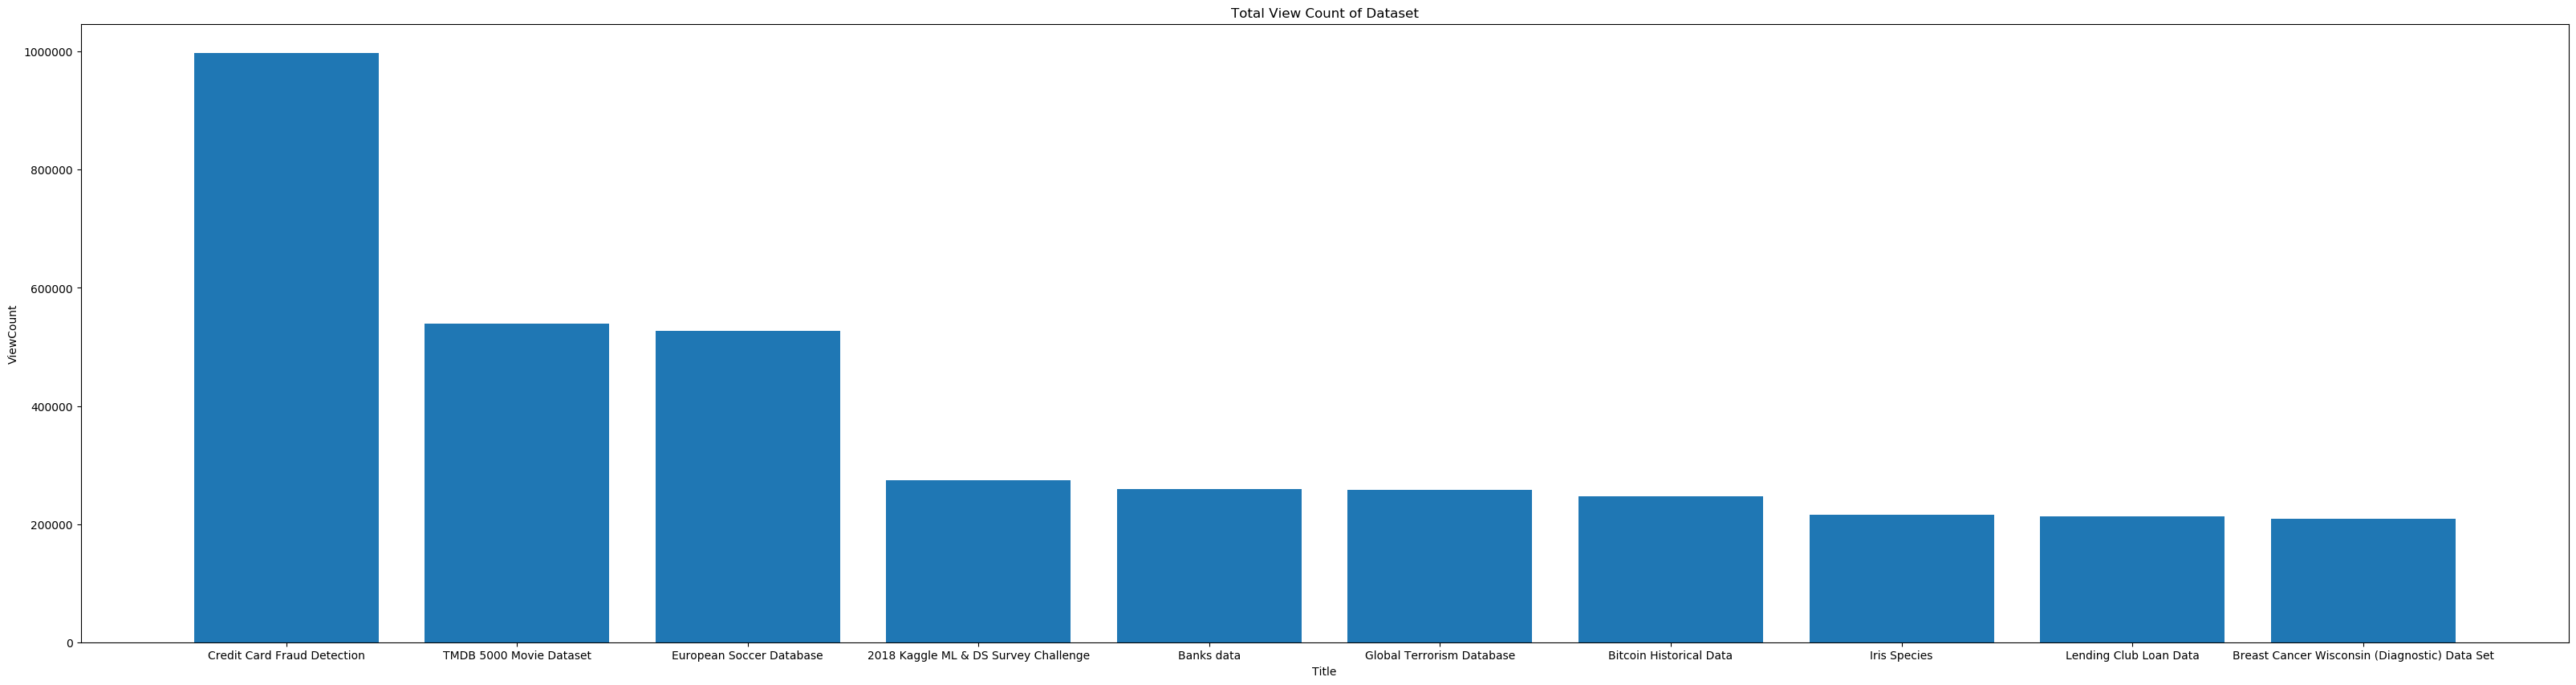

In [35]:
plt.rcdefaults()
aa=[]
xaxis=[]
yaxis=[]
aa=np.array(df["viewCount"].nlargest(10))
ser=pd.Series(aa)
for i in range(len(ser)):
    listOfPositions = getVCIndexes(df, ser[i]) 
    yaxis.append(ser[i])
    
    for j in range(len(listOfPositions)):
        
        y=np.array(listOfPositions[j])
        
        z=int(y[j])
        print('Title %s in Dataframe  total View Count %s'%(df.iloc[z,32],ser[i]))
        xaxis.append(df.iloc[z,32])
print("")
plt.figure(figsize=(40,10))
plt.xticks(range(len(xaxis)),xaxis)
plt.xlabel("Title")
plt.ylabel('ViewCount')
plt.title('Total View Count of Dataset')
plt.bar(range(len(yaxis)),yaxis)
plt.show()

Title European Soccer Database in Dataframe  total Topic Count 87
Title TMDB 5000 Movie Dataset in Dataframe  total Topic Count 50
Title Data Science for Good: Kiva Crowdfunding in Dataframe  total Topic Count 47
Title Data Science for Good: DonorsChoose.org in Dataframe  total Topic Count 39
Title Medical Appointment No Shows in Dataframe  total Topic Count 37
Title Credit Card Fraud Detection in Dataframe  total Topic Count 35
Title Meta Kaggle in Dataframe  total Topic Count 32
Title Lending Club Loan Data in Dataframe  total Topic Count 29
Title Every Cryptocurrency Daily Market Price in Dataframe  total Topic Count 28
Title Data Science for Good: Center for Policing Equity in Dataframe  total Topic Count 27



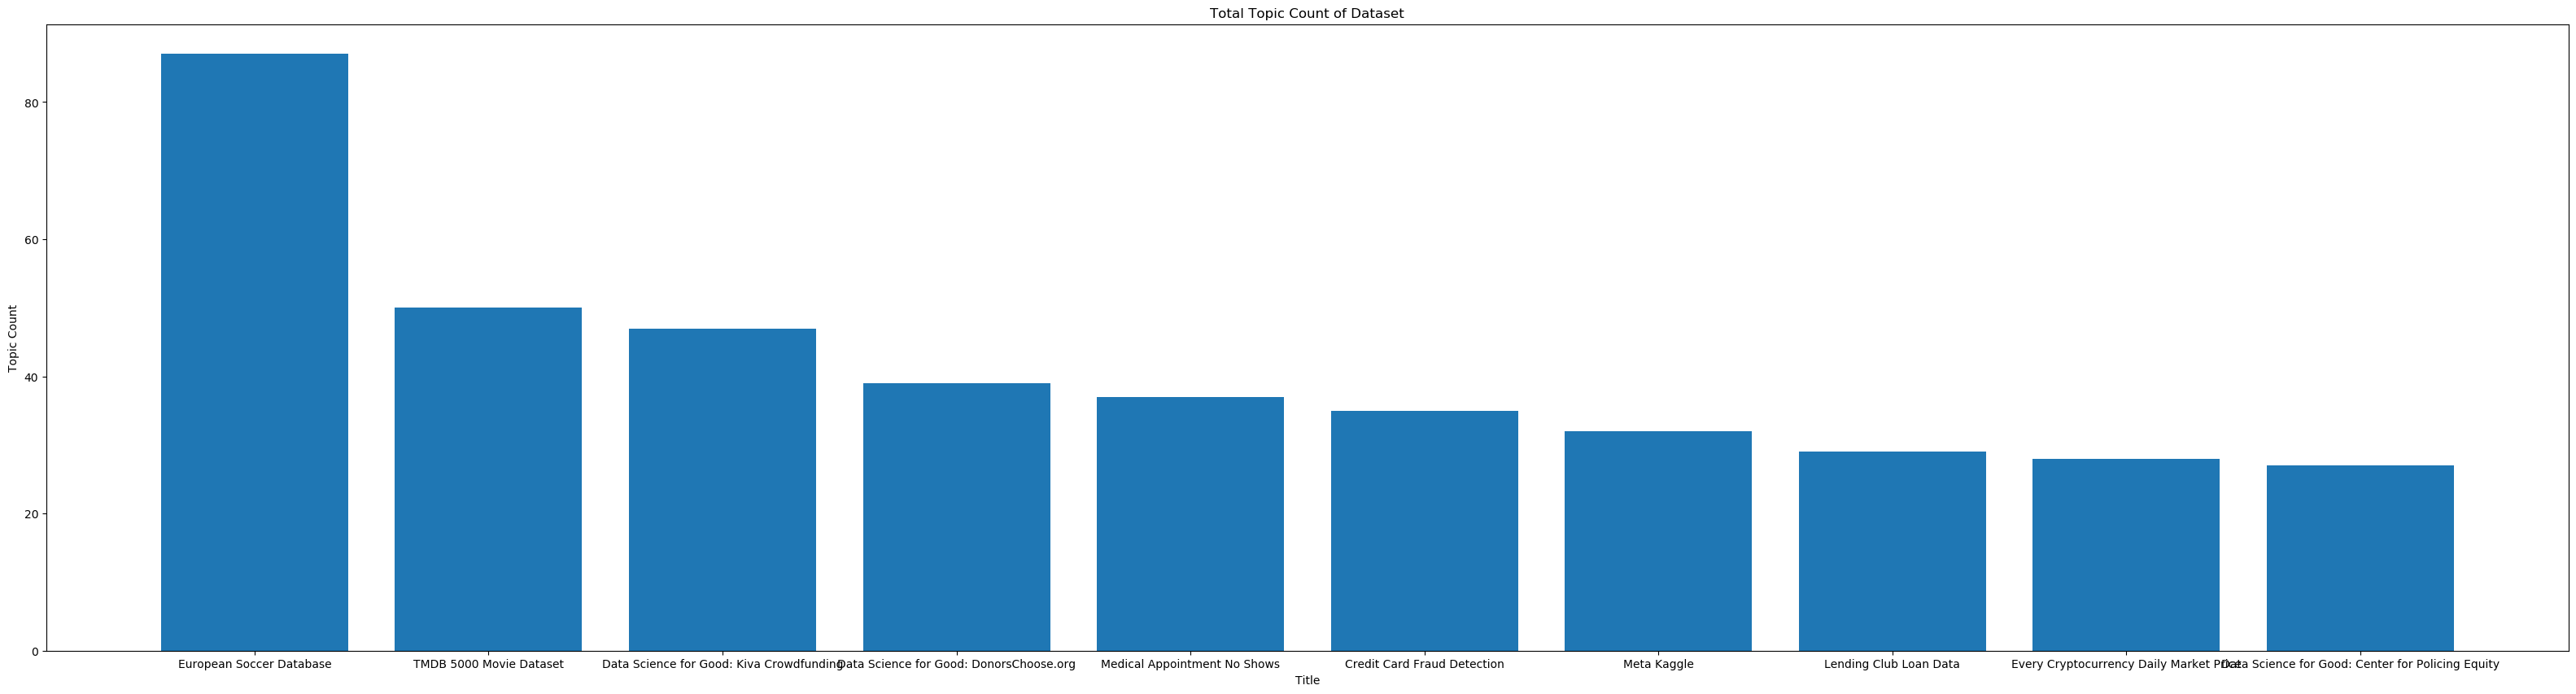

<Figure size 640x480 with 0 Axes>

In [36]:
#from PIL import Image
#import cv2
#img=Image.open('Topic_count.png')
plt.rcdefaults()
aa=[]
xaxis=[]
yaxis=[]
aa=np.array(df["topicCount"].nlargest(10))
ser=pd.Series(aa)
for i in range(len(ser)):
    listOfPositions = getTCIndexes(df, ser[i]) 
    yaxis.append(ser[i])
    
    for j in range(len(listOfPositions)):
        
        y=np.array(listOfPositions[j])
        
        z=int(y[j])
        print('Title %s in Dataframe  total Topic Count %s'%(df.iloc[z,32],ser[i]))
        xaxis.append(df.iloc[z,32])
print("")
plt.figure(figsize=(40,10))
plt.xticks(range(len(xaxis)),xaxis)
plt.xlabel("Title")
plt.ylabel('Topic Count')
plt.title('Total Topic Count of Dataset')
plt.bar(range(len(yaxis)),yaxis)
plt.rc('axes',prop_cycle=(plt.cycler('color',['r','b','g','y'])))
plt.show()
plt.savefig('Topic_count.png',transparent=False)
#img=Image.open('Topic_count.png')
#img=cv2.imread(Topic_count)

In [95]:
kaggle.query('downloadCount<10').iloc[:,:12]


,categories,commonFileTypes,creatorName,creatorUrl,creatorUserId,currentDatasetVersionId,currentDatasetVersionNumber,datasetId,datasetSize,datasetUrl,dateUpdated,diffType
1,"{'categories': [{'id': 13205, 'name': 'text mi...","[{'fileType': 'other', 'count': 20, 'totalSize...",Jason King,/jkkphys,459483,194523,1,83790,968989653,/jkkphys/english-wikipedia-articles-20170820-m...,2018-11-28T17:09:32.423Z,versioned
10,"{'categories': [{'id': 11110, 'name': 'governm...","[{'fileType': 'other', 'count': 1, 'totalSize'...",Paul Mooney,/paultimothymooney,1314380,28353,1,22069,168762576,/census/census-bureau-usa,2018-04-17T18:52:46.35Z,realtime
24,"{'categories': [{'id': 7105, 'name': 'neurosci...","[{'fileType': 'csv', 'count': 2, 'totalSize': ...",Jason Miller,/millerintllc,419590,194940,4,83976,2339940,/millerintllc/eeg-microexperiment,2018-11-29T03:36:37.857Z,unversioned
27,"{'categories': [{'id': 11121, 'name': 'politic...","[{'fileType': 'csv', 'count': 1, 'totalSize': ...",Thomas Edge,/thomascedge,2291849,192185,1,82687,124542,/thomascedge/september-2018-trump-tweets,2018-11-26T13:15:15.24Z,versioned
30,"{'categories': [{'id': 7403, 'name': 'climate'...","[{'fileType': 'csv', 'count': 2, 'totalSize': ...",Kaggle Team,/kaggleteam,1,194364,91,56624,16451,/fivethirtyeight/fivethirtyeight-mad-men-dataset,2018-11-28T15:05:32.527Z,versioned
...,...,...,...,...,...,...,...,...,...,...,...,...
13015,"{'categories': [{'id': 11205, 'name': 'economi...","[{'fileType': 'csv', 'count': 3, 'totalSize': ...",Kaggle Team,/kaggleteam,1,185511,71,68477,7684,/bls/index-of-aggregate-weekly-hours,2018-11-19T18:17:08.037Z,versioned
13016,"{'categories': [{'id': 11205, 'name': 'economi...","[{'fileType': 'json', 'count': 2, 'totalSize':...",Kaggle Team,/kaggleteam,1,185512,70,68478,6729,/bls/indexes-of-aggregate-weekly-payrolls,2018-11-19T18:17:18.11Z,versioned
13017,"{'categories': [{'id': 11205, 'name': 'economi...","[{'fileType': 'json', 'count': 3, 'totalSize':...",Kaggle Team,/kaggleteam,1,185483,72,68454,16215,/bls/civilian-employment-level-and-ratio,2018-11-19T18:04:30.14Z,versioned
13018,"{'categories': [], 'type': 'dataset'}","[{'fileType': 'other', 'count': 26, 'totalSize...",tushar,/tnand5080,2129416,185484,1,79734,4447106,/tnand5080/test-d,2018-11-19T18:05:29.583Z,versioned


In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [72]:
from sklearn.mixture import GaussianMixture

In [73]:
df=pd.read_csv('Downloads/all_kaggle_datasets.csv')


In [74]:
df.shape

(13020, 37)

Text(0.5, 1.0, 'dataset downloadcount')

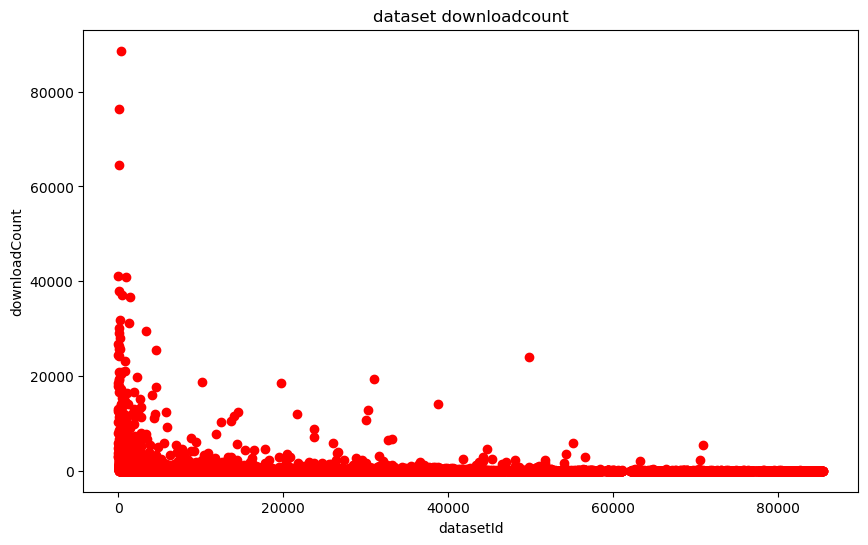

In [75]:
plt.figure(figsize=(10,6))
plt.scatter(df['datasetId'],df['downloadCount'])
plt.xlabel('datasetId')
plt.ylabel('downloadCount')
plt.title('dataset downloadcount')

In [76]:
X=df.iloc[:,[7,12]].values
X[:5]

array([[70947,  5506],
       [83790,     7],
       [38809, 14066],
       [45286,  2573],
       [28335,   517]], dtype=int64)

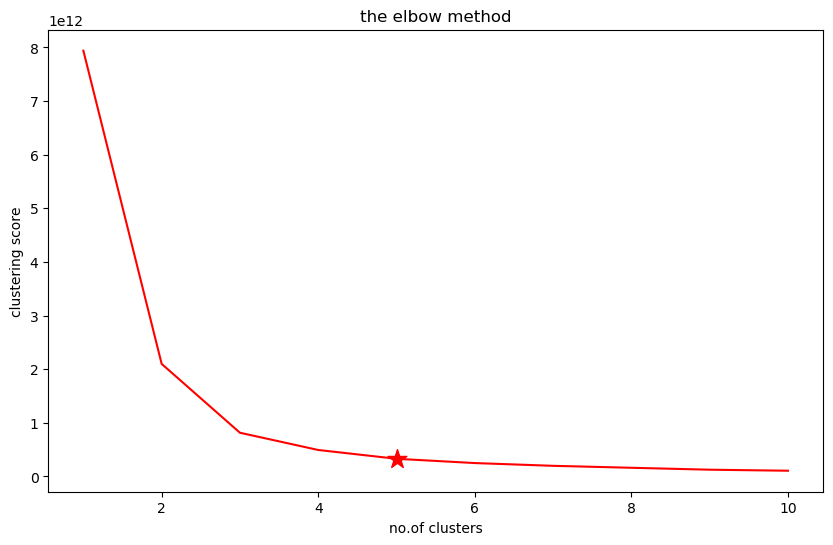

In [79]:
clustering_score=[]
for i in range(1,11):
    kmeans=KMeans(n_clusters=i,init='random',random_state=42)
    kmeans.fit(X)
    clustering_score.append(kmeans.inertia_)

plt.figure(figsize=(10,6))
plt.plot(range(1,11),clustering_score)
plt.scatter(5,clustering_score[4],s=200,c='red',marker='*')
plt.title('the elbow method')
plt.xlabel('no.of clusters')
plt.ylabel('clustering score')
plt.show()

In [80]:
kmeans=KMeans(n_clusters=5,random_state=42)
kmeans.fit(X)
pred=kmeans.predict(X)
pred


array([2, 2, 0, ..., 2, 2, 2])

In [81]:
df['Cluster']=pd.DataFrame(pred,columns=['cluster'])
print('number of datapoints in each cluster=\n',df['Cluster'].value_counts())
df

number of datapoints in each cluster=
 1    4531
0    2787
3    2371
4    1807
2    1524
Name: Cluster, dtype: int64


,categories,commonFileTypes,creatorName,creatorUrl,creatorUserId,currentDatasetVersionId,currentDatasetVersionNumber,datasetId,datasetSize,datasetUrl,...,ownerUserId,scriptCount,scriptsUrl,thumbnailImageUrl,title,topicCount,type,viewCount,voteButton,Cluster
0,"{'categories': [{'id': 13213, 'name': 'survey ...","[{'fileType': 'csv', 'count': 3, 'totalSize': ...",Paul Mooney,/paultimothymooney,1314380,161079,5,70947,4043536,/kaggle/kaggle-survey-2018,...,NaN,190,/kaggle/kaggle-survey-2018/kernels,https://storage.googleapis.com/kaggle-datasets...,2018 Kaggle ML & DS Survey Challenge,12,fileset,274306,"{'totalVotes': 678, 'hasAlreadyVotedUp': False...",2
1,"{'categories': [{'id': 13205, 'name': 'text mi...","[{'fileType': 'other', 'count': 20, 'totalSize...",Jason King,/jkkphys,459483,194523,1,83790,968989653,/jkkphys/english-wikipedia-articles-20170820-m...,...,459483.0,11,/jkkphys/english-wikipedia-articles-20170820-m...,https://storage.googleapis.com/kaggle-datasets...,English Wikipedia Articles 2017-08-20 Models,0,fileset,176,"{'totalVotes': 2, 'hasAlreadyVotedUp': False, ...",2
2,"{'categories': [{'id': 11102, 'name': 'busines...","[{'fileType': 'csv', 'count': 1, 'totalSize': ...",Mehdi Dagdoug,/mehdidag,1227281,59109,1,38809,5621145,/mehdidag/black-friday,...,1227281.0,40,/mehdidag/black-friday/kernels,https://storage.googleapis.com/kaggle-datasets...,Black Friday,4,fileset,80770,"{'totalVotes': 298, 'hasAlreadyVotedUp': False...",0
3,"{'categories': [{'id': 1209, 'name': 'governme...","[{'fileType': 'other', 'count': 1, 'totalSize'...",Chris Crawford,/crawford,484516,150301,18,45286,45177047,/center-for-policing-equity/data-science-for-good,...,NaN,54,/center-for-policing-equity/data-science-for-g...,https://storage.googleapis.com/kaggle-datasets...,Data Science for Good: Center for Policing Equity,27,fileset,52192,"{'totalVotes': 282, 'hasAlreadyVotedUp': False...",0
4,"{'categories': [{'id': 2200, 'name': 'arts and...","[{'fileType': 'other', 'count': 2, 'totalSize'...",Danil,/thedownhill,1914606,36285,2,28335,609430422,/thedownhill/art-images-drawings-painting-scul...,...,1914606.0,5,/thedownhill/art-images-drawings-painting-scul...,https://storage.googleapis.com/kaggle-datasets...,Art Images: Drawing/Painting/Sculptures/Engrav...,0,fileset,4086,"{'totalVotes': 42, 'hasAlreadyVotedUp': False,...",0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13015,"{'categories': [{'id': 11205, 'name': 'economi...","[{'fileType': 'csv', 'count': 3, 'totalSize': ...",Kaggle Team,/kaggleteam,1,185511,71,68477,7684,/bls/index-of-aggregate-weekly-hours,...,NaN,1,/bls/index-of-aggregate-weekly-hours/kernels,https://storage.googleapis.com/kaggle-datasets...,Index of Aggregate Weekly Hours,0,fileset,17,"{'totalVotes': 1, 'hasAlreadyVotedUp': False, ...",2
13016,"{'categories': [{'id': 11205, 'name': 'economi...","[{'fileType': 'json', 'count': 2, 'totalSize':...",Kaggle Team,/kaggleteam,1,185512,70,68478,6729,/bls/indexes-of-aggregate-weekly-payrolls,...,NaN,1,/bls/indexes-of-aggregate-weekly-payrolls/kernels,https://storage.googleapis.com/kaggle-datasets...,Indexes of Aggregate Weekly Payrolls,0,fileset,13,"{'totalVotes': 1, 'hasAlreadyVotedUp': False, ...",2
13017,"{'categories': [{'id': 11205, 'name': 'economi...","[{'fileType': 'json', 'count': 3, 'totalSize':...",Kaggle Team,/kaggleteam,1,185483,72,68454,16215,/bls/civilian-employment-level-and-ratio,...,NaN,1,/bls/civilian-employment-level-and-ratio/kernels,https://storage.googleapis.com/kaggle-datasets...,Civilian Employment Level and Ratio,0,fileset,24,"{'totalVotes': 1, 'hasAlreadyVotedUp': False, ...",2
13018,"{'categories': [], 'type': 'dataset'}","[{'fileType': 'other', 'count': 26, 'totalSize...",tushar,/tnand5080,2129416,185484,1,79734,4447106,/tnand5080/test-d,...,2129416.0,2,/tnand5080/test-d/kernels,https://storage.googleapis.com/kaggle-datasets...,test_d,0,fileset,8,"{'totalVotes': 0, 'hasAlreadyVotedUp': False, ...",2


Text(0.5, 1.0, 'datasets cluster')

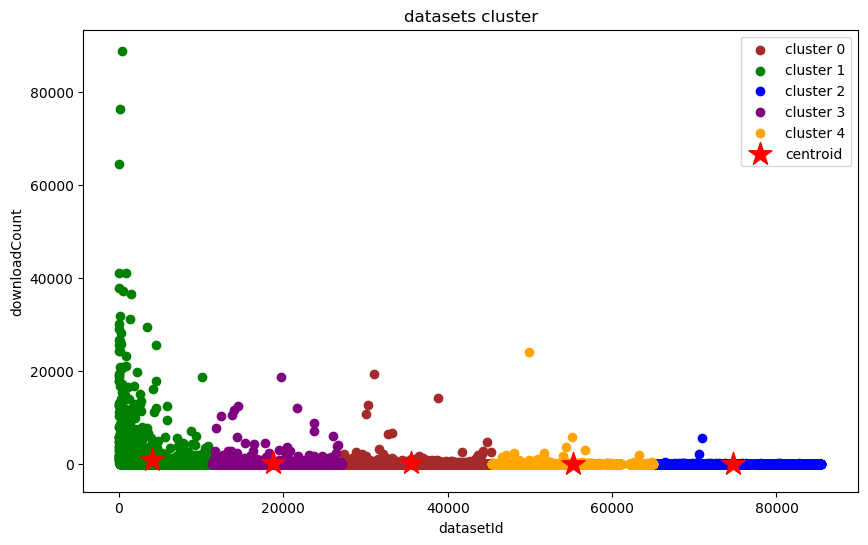

In [82]:
plt.figure(figsize=(10,6))
plt.scatter(X[pred==0,0],X[pred==0,1],c='brown',label='cluster 0')
plt.scatter(X[pred==1,0],X[pred==1,1],c='green',label='cluster 1')
plt.scatter(X[pred==2,0],X[pred==2,1],c='blue',label='cluster 2')
plt.scatter(X[pred==3,0],X[pred==3,1],c='purple',label='cluster 3')
plt.scatter(X[pred==4,0],X[pred==4,1],c='orange',label='cluster 4')

plt.scatter(kmeans.cluster_centers_[:,0],kmeans.cluster_centers_[:,1],s=300,c='red',label='centroid',marker='*')
plt.xlabel('datasetId')
plt.ylabel('downloadCount')
plt.legend()
plt.title('datasets cluster')


In [104]:
df=pd.read_csv('Downloads/all_kaggle_datasets.csv')
data=df.values[0:-1]
categories=df.values[0:-1]
print(data)
print(categories)


[["{'categories': [{'id': 13213, 'name': 'survey analysis', 'fullPath': 'analysis > survey analysis', 'listingUrl': '/datasets?group=public&tagids=13213', 'description': None, 'isInherited': False, 'datasetCount': 18, 'competitionCount': 0, 'scriptCount': 105, 'totalCount': 123, 'tagUrl': '/tags/survey-analysis'}], 'type': 'dataset'}"
  "[{'fileType': 'csv', 'count': 3, 'totalSize': 42559129}]"
  'Paul Mooney' ... 'fileset' 274306
  "{'totalVotes': 678, 'hasAlreadyVotedUp': False, 'hasAlreadyVotedDown': False, 'canUpvote': False, 'canDownvote': False, 'voteUpUrl': '/kaggle/kaggle-survey-2018/vote', 'voteDownUrl': None, 'voters': [], 'currentUserInfo': None, 'showVoters': False, 'alwaysShowVoters': False}"]
 ["{'categories': [{'id': 13205, 'name': 'text mining', 'fullPath': 'analysis > text mining', 'listingUrl': '/datasets?group=public&tagids=13205', 'description': None, 'isInherited': False, 'datasetCount': 41, 'competitionCount': 0, 'scriptCount': 209, 'totalCount': 250, 'tagUrl': '/

In [56]:
doc=e.split(",")
res = [*set(doc)]


In [50]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

In [57]:
vectorizer = TfidfVectorizer(stop_words='english')
XY = vectorizer.fit_transform(res)

In [58]:
true_k = 5
model = KMeans(n_clusters=true_k, init='k-means++', max_iter=100, n_init=1)
model.fit(XY)

KMeans(algorithm='auto', copy_x=True, init='k-means++', max_iter=100,
       n_clusters=5, n_init=1, n_jobs=None, precompute_distances='auto',
       random_state=None, tol=0.0001, verbose=0)

Top terms per cluster:
Cluster 0:
 research
 water
 science
 sports
 information
 government
 mathematics
 education
 industry
 programming
 life
 design
 surgery
 society
 networks
Cluster 1:
 computer
 model
 security
 architecture
 diagnosis
 science
 interaction
 pre
 trained
 human
 faith
 environment
 finance
 energy
 engineering
Cluster 2:
 transport
 rail
 road
 public
 writing
 europe
 energy
 engineering
 engines
 entertainment
 environment
 estate
 ethics
 ethnic
 experimental
Cluster 3:
 data
 sciences
 analysis
 games
 health
 regression
 engineering
 learning
 video
 object
 culture
 cleaning
 tabular
 categorical
 visualization
Cluster 4:
 web
 mobile
 sites
 writing
 exercise
 engines
 entertainment
 environment
 estate
 ethics
 ethnic
 europe
 experimental
 energy
 faith


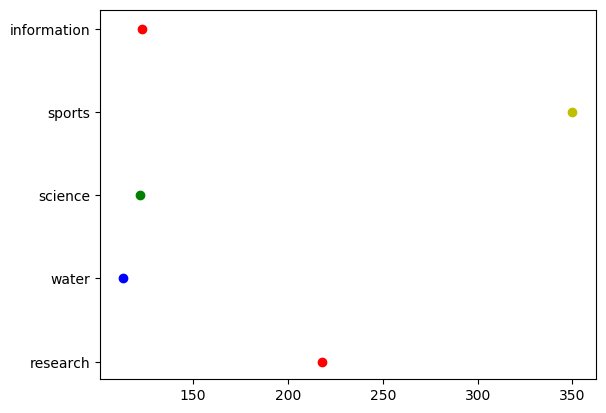

In [165]:
print("Top terms per cluster:")
cwords=[]

order_centroids = model.cluster_centers_.argsort()[:, ::-1]
terms = vectorizer.get_feature_names()
for i in range(true_k):
    print("Cluster %d:" % i),
    for ind in order_centroids[i, :15]:
        cwords.append(terms[ind])
        print(' %s' % terms[ind]),
    plt.scatter(ind,cwords[i])

plt.show()

print("\n")


In [140]:
from sklearn.decomposition import LatentDirichletAllocation

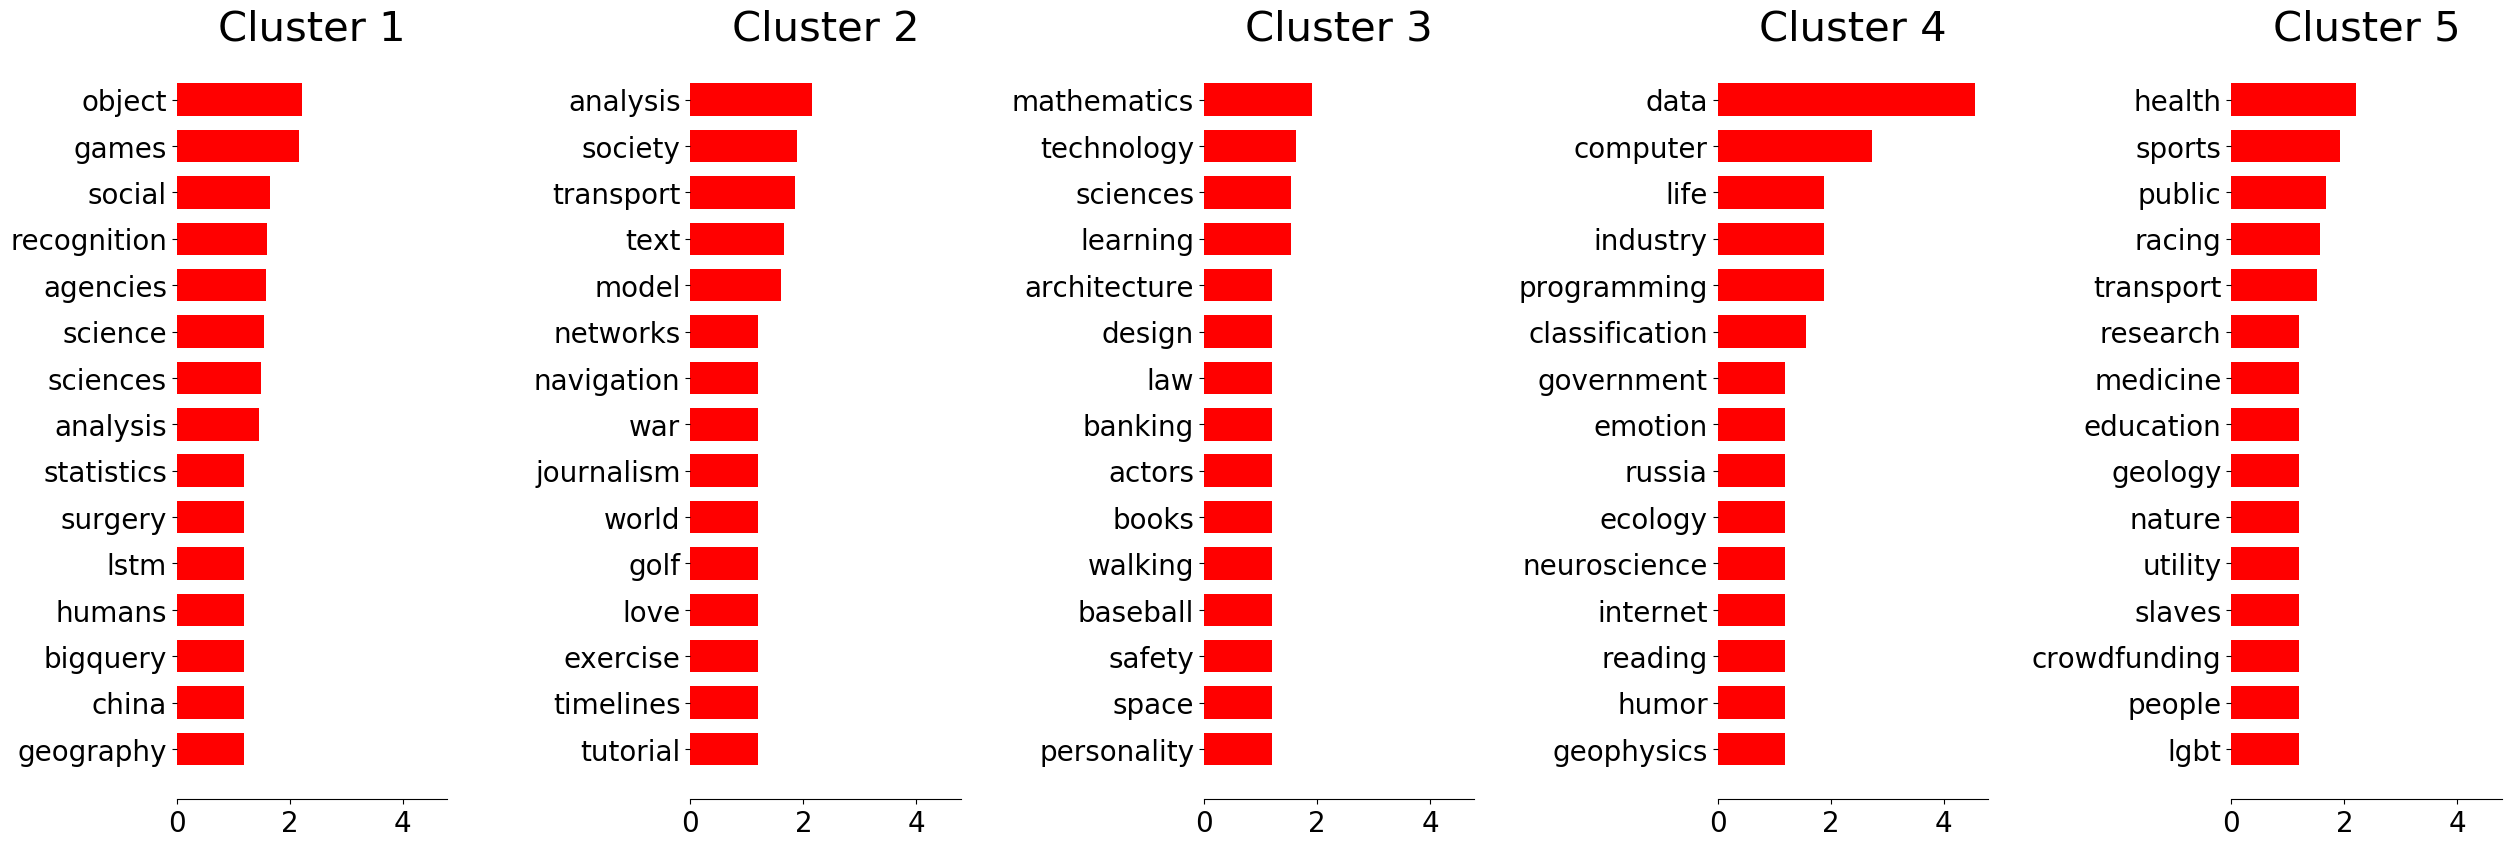

In [167]:
lda = LatentDirichletAllocation(n_components=5, learning_decay=0.9)
X_lda = lda.fit(XY)

def plot_top_words(model, feature_names, n_top_words, title):
    fig, axes = plt.subplots(1, 5, figsize=(30,30), sharex=True)
    axes = axes.flatten()
    for topic_idx, topic in enumerate(model.components_):
        top_features_ind = topic.argsort()[:-n_top_words - 1:-1]
        top_features = [feature_names[i] for i in top_features_ind]
        weights = topic[top_features_ind]

        ax = axes[topic_idx]
        ax.barh(top_features, weights, height=0.7)
        ax.set_title(f'Cluster {topic_idx +1}',
                     fontdict={'fontsize': 30})
        ax.invert_yaxis()
        ax.tick_params(axis='both', which='major', labelsize=20)
        for i in 'top right left'.split():
            ax.spines[i].set_visible(False)
        fig.suptitle(title, fontsize=40)
    plt.subplots_adjust(top=0.30, bottom=0.05, wspace=0.90, hspace=0.3)
    plt.show()
    
n_top_words = 15
feature_names = vectorizer.get_feature_names()
plot_top_words(X_lda, feature_names, n_top_words, '')
    